# Tugas Praktikum Deep Learning — Tugas 2: Fashion-MNIST Classification (PyTorch)

| | |
|---|---|
| **Nama** | Faiz Farrosian Karim |
| **NRP** | 5054251027 |
| **Framework** | PyTorch |
| **Dataset** | [Fashion-MNIST](https://www.kaggle.com/datasets/zalando-research/fashionmnist) |

**Tujuan:** mengklasifikasikan 10 jenis pakaian dari gambar grayscale 28×28 dan membandingkan tiga model:

1. ANN (baseline)
2. CNN sederhana
3. CNN dengan Batch Normalization dan Dropout

Model terbaik disimpan di akhir notebook untuk tugas Deployment.

## 1. Import Library & Konfigurasi

In [1]:
import time, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)
sns.set_style("white")
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

PyTorch: 2.15.0+cpu | device: cpu


## 2. Load Data & Eksplorasi

Dataset CSV: kolom pertama `label` (0–9), 784 kolom berikutnya adalah piksel (28×28) bernilai 0–255. Data train (60.000) dan test (10.000) sudah terpisah.

In [2]:
import glob
def find(fn):
    c = glob.glob(fn) + glob.glob(f"/content/**/{fn}", recursive=True) + glob.glob(f"/kaggle/input/**/{fn}", recursive=True)
    assert c, f"{fn} tidak ditemukan. Upload ke Colab (panel Files) atau tambahkan dataset di Kaggle."
    return c[0]
train_df = pd.read_csv(find("fashion-mnist_train.csv"))
test_df  = pd.read_csv(find("fashion-mnist_test.csv"))
print("Train:", train_df.shape, "| Test:", test_df.shape)

X_all = train_df.iloc[:, 1:].values.astype("float32") / 255.0   # normalisasi ke [0, 1]
y_all = train_df.iloc[:, 0].values.astype("int64")
X_test = test_df.iloc[:, 1:].values.astype("float32") / 255.0
y_test = test_df.iloc[:, 0].values.astype("int64")
print("Rentang piksel:", X_all.min(), "-", X_all.max())
print("Distribusi kelas (train):", np.bincount(y_all))

Train: (60000, 785) | Test: (10000, 785)
Rentang piksel: 0.0 - 1.0
Distribusi kelas (train): [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


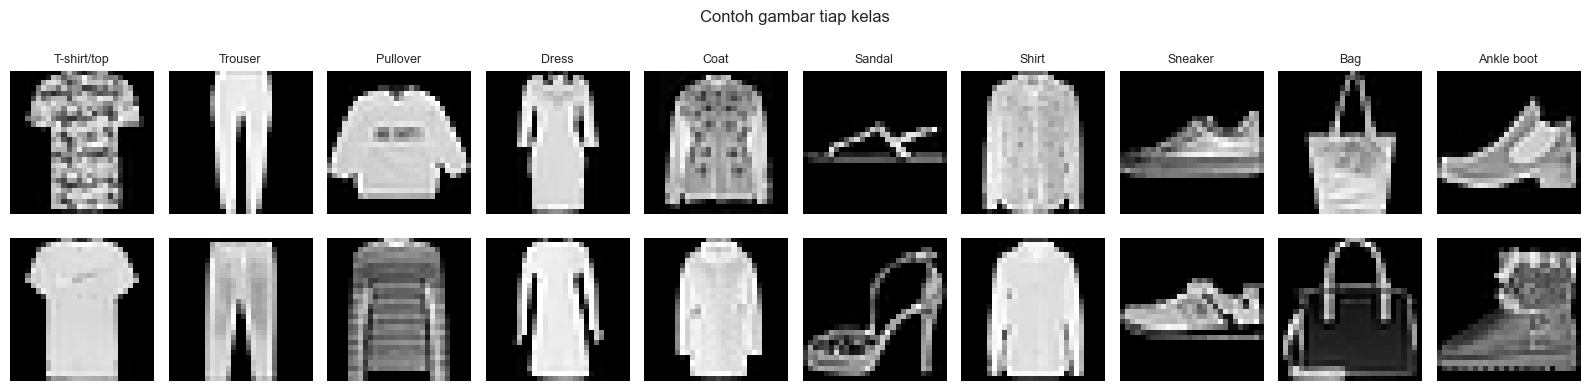

In [3]:
fig, ax = plt.subplots(2, 10, figsize=(16, 4.2))
for c in range(10):
    idx = np.where(y_all == c)[0]
    for r in range(2):
        ax[r, c].imshow(X_all[idx[r]].reshape(28, 28), cmap="gray"); ax[r, c].axis("off")
    ax[0, c].set_title(CLASS_NAMES[c], fontsize=9)
plt.suptitle("Contoh gambar tiap kelas"); plt.tight_layout(); plt.show()

Dataset ini **seimbang** (tiap kelas 6.000 gambar di train), sehingga *accuracy* adalah metrik utama yang layak dipakai, dilengkapi macro-F1 dan confusion matrix.

## 3. Preprocessing & DataLoader

- Train dipecah menjadi **54.000 train** dan **6.000 validation** (stratified); data test asli dipakai hanya untuk evaluasi akhir.
- **ANN** membutuhkan input *flat* `(N, 784)`, sedangkan **CNN** membutuhkan input berbentuk `(N, 1, 28, 28)` (channel-first di PyTorch).
- Agar tidak menggandakan data, kita simpan tensor dalam bentuk `(N, 1, 28, 28)` dan ANN melakukan `nn.Flatten()` di dalam modelnya.

In [4]:
X_tr, X_val, y_tr, y_val = train_test_split(X_all, y_all, test_size=0.10, stratify=y_all, random_state=SEED)
to4d = lambda a: torch.tensor(a).view(-1, 1, 28, 28)
BS = 128
def loader(X, y, shuffle=False, bs=BS):
    return DataLoader(TensorDataset(to4d(X), torch.tensor(y)), batch_size=bs, shuffle=shuffle)
train_loader, val_loader, test_loader = loader(X_tr, y_tr, True), loader(X_val, y_val, bs=512), loader(X_test, y_test, bs=512)
print("Train/Val/Test:", len(X_tr), len(X_val), len(X_test))
xb, yb = next(iter(train_loader)); print("Batch shape:", xb.shape, yb.shape)

Train/Val/Test: 54000 6000 10000
Batch shape: torch.Size([128, 1, 28, 28]) torch.Size([128])


## 4. Fungsi Bantu (Training, Evaluasi, Learning Curve)

In [5]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb); loss = criterion(out, yb)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * len(xb); correct += (out.argmax(1) == yb).sum().item(); n += len(xb)
    return total / n, correct / n

def fit(model, epochs, lr=1e-3, name="model"):
    model.to(device)
    criterion = nn.CrossEntropyLoss(); optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
    best, best_state, t0 = float("inf"), None, time.time()
    for ep in range(epochs):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(hist, (tl, vl, ta, va)): hist[k].append(v)
        if vl < best: best, best_state = vl, {k: v.clone() for k, v in model.state_dict().items()}
        print(f"[{name}] epoch {ep+1:02d}/{epochs}  loss={tl:.4f} acc={ta:.4f} | val_loss={vl:.4f} val_acc={va:.4f}")
    model.load_state_dict(best_state)
    hist["time"] = time.time() - t0
    print(f"[{name}] selesai {hist['time']:.0f}s | val_loss terbaik={best:.4f} pada epoch {int(np.argmin(hist['val_loss']))+1}")
    return hist

def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4)); ep = range(1, len(hist["loss"]) + 1)
    ax[0].plot(ep, hist["loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="validation")
    ax[0].set(title=f"{title} — Loss", xlabel="Epoch", ylabel="Loss"); ax[0].legend()
    ax[1].plot(ep, hist["acc"], label="train"); ax[1].plot(ep, hist["val_acc"], label="validation")
    ax[1].set(title=f"{title} — Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend()
    plt.tight_layout(); plt.show()

results, preds = {}, {}
@torch.no_grad()
def evaluate(model, name):
    model.eval(); p = []
    for xb, _ in test_loader: p.append(model(xb.to(device)).argmax(1).cpu().numpy())
    p = np.concatenate(p); preds[name] = p
    results[name] = {"Test Accuracy": accuracy_score(y_test, p), "Macro F1": f1_score(y_test, p, average="macro"),
                     "Params": sum(q.numel() for q in model.parameters())}
    print(classification_report(y_test, p, target_names=CLASS_NAMES, digits=3))
    plt.figure(figsize=(8, 6.5)); sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES); plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.xticks(rotation=45, ha="right"); plt.show()

## 5. Model 1 — ANN (Baseline)

Input `(N, 1, 28, 28)` diratakan menjadi `(N, 784)` oleh `nn.Flatten()`, lalu dua hidden layer *fully connected*. Output berupa 10 logit (softmax sudah ada di dalam `CrossEntropyLoss`).

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Linear(in_features=128, out_features=10, bias=True)
)
[ANN] epoch 01/12  loss=0.5862 acc=0.7934 | val_loss=0.4435 val_acc=0.8400
[ANN] epoch 02/12  loss=0.4021 acc=0.8541 | val_loss=0.3789 val_acc=0.8655
[ANN] epoch 03/12  loss=0.3534 acc=0.8718 | val_loss=0.3516 val_acc=0.8733
[ANN] epoch 04/12  loss=0.3266 acc=0.8816 | val_loss=0.3468 val_acc=0.8727
[ANN] epoch 05/12  loss=0.3097 acc=0.8866 | val_loss=0.3481 val_acc=0.8718
[ANN] epoch 06/12  loss=0.2891 acc=0.8934 | val_loss=0.3269 val_acc=0.8805
[ANN] epoch 07/12  loss=0.2768 acc=0.8983 | val_loss=0.3268 val_acc=0.8785
[ANN] epoch 08/12  loss=0.2648 acc=0.9019 | val_loss=0.3579 val_acc=0.8662
[ANN] epoch 09/12  loss=0.2543 acc=0.9048 | val_loss=0.3227 val_acc=0.8830
[ANN] epoch 10/12  loss=0.2438 acc=0.9087 | val_loss=0.3181 val_

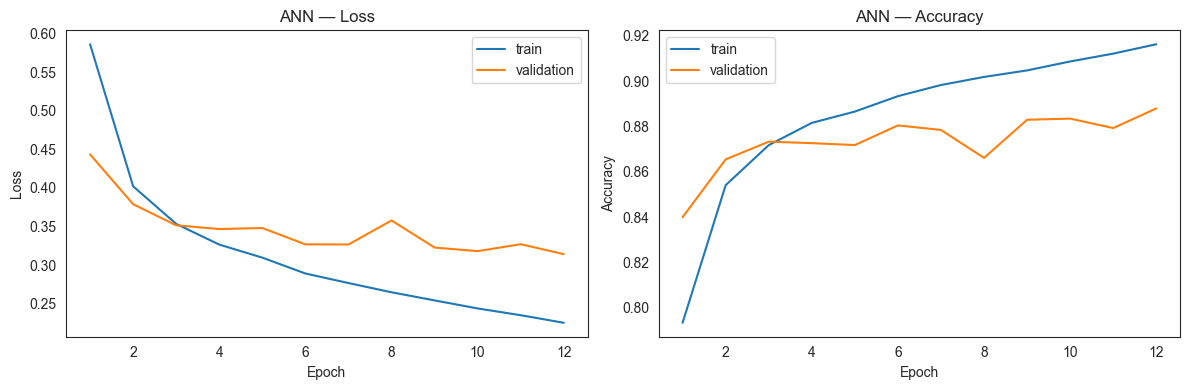

              precision    recall  f1-score   support

 T-shirt/top      0.868     0.794     0.829      1000
     Trouser      0.986     0.987     0.987      1000
    Pullover      0.839     0.813     0.826      1000
       Dress      0.890     0.930     0.910      1000
        Coat      0.839     0.838     0.838      1000
      Sandal      0.977     0.938     0.957      1000
       Shirt      0.693     0.756     0.723      1000
     Sneaker      0.932     0.932     0.932      1000
         Bag      0.983     0.962     0.972      1000
  Ankle boot      0.928     0.966     0.947      1000

    accuracy                          0.892     10000
   macro avg      0.893     0.892     0.892     10000
weighted avg      0.893     0.892     0.892     10000



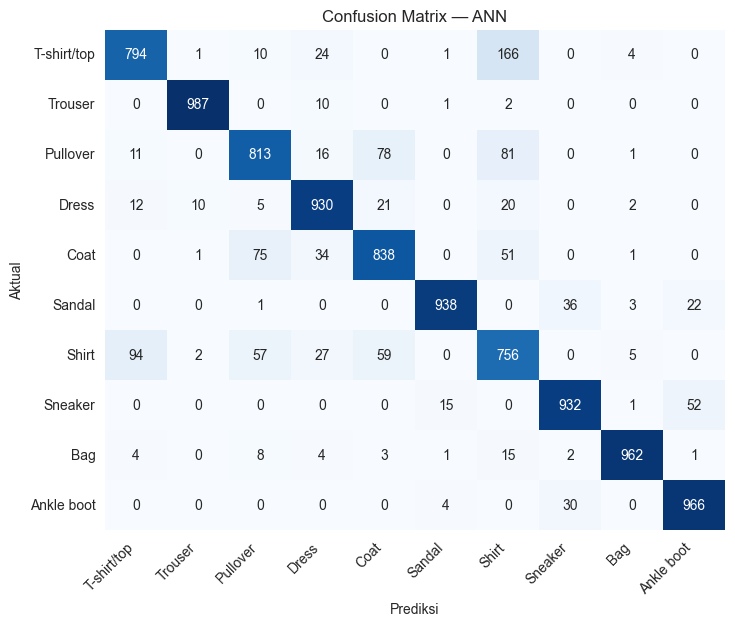

In [6]:
EPOCHS = 12
torch.manual_seed(SEED)
ann = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))
print(ann)
h_ann = fit(ann, EPOCHS, name="ANN")
plot_history(h_ann, "ANN")
evaluate(ann, "ANN")

## 6. Model 2 — CNN Sederhana

Dua blok Conv → ReLU → MaxPool untuk mengekstrak fitur spasial, kemudian classifier fully connected. Input tetap `(N, 1, 28, 28)` tanpa di-flatten.

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=3136, out_features=128, bias=True)
  (8): ReLU()
  (9): Linear(in_features=128, out_features=10, bias=True)
)
[CNN] epoch 01/12  loss=0.5509 acc=0.8014 | val_loss=0.4042 val_acc=0.8560
[CNN] epoch 02/12  loss=0.3372 acc=0.8789 | val_loss=0.3169 val_acc=0.8858
[CNN] epoch 03/12  loss=0.2900 acc=0.8955 | val_loss=0.2825 val_acc=0.9007
[CNN] epoch 04/12  loss=0.2614 acc=0.9046 | val_loss=0.3470 val_acc=0.8748
[CNN] epoch 05/12  loss=0.2368 acc=0.9141 | val_loss=0.2595 val_acc=0.9013
[CNN] epoch 06/12  loss=0.2174 acc=0.9198 | val_loss=0.2494 val_acc=0.9078
[CNN] epoch 07/12  loss=0

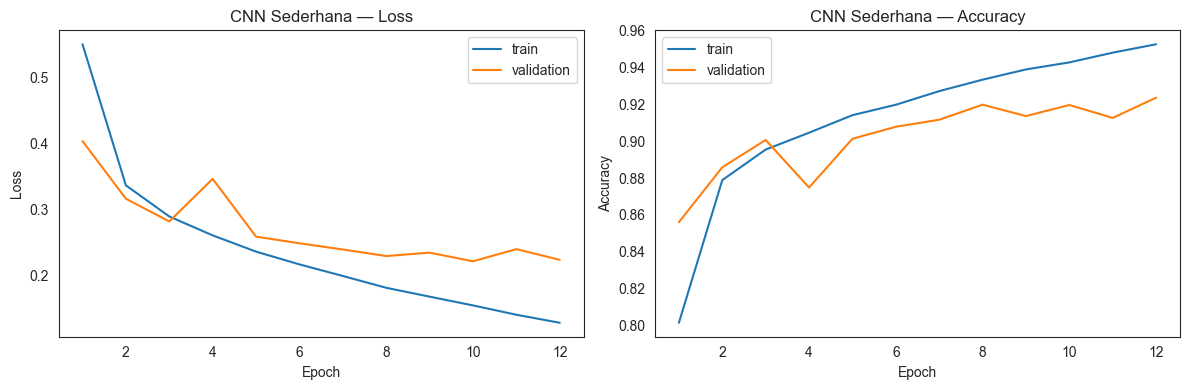

              precision    recall  f1-score   support

 T-shirt/top      0.840     0.915     0.876      1000
     Trouser      0.994     0.987     0.990      1000
    Pullover      0.882     0.895     0.888      1000
       Dress      0.938     0.924     0.931      1000
        Coat      0.887     0.888     0.888      1000
      Sandal      0.981     0.986     0.984      1000
       Shirt      0.812     0.748     0.779      1000
     Sneaker      0.970     0.952     0.961      1000
         Bag      0.989     0.981     0.985      1000
  Ankle boot      0.957     0.974     0.965      1000

    accuracy                          0.925     10000
   macro avg      0.925     0.925     0.925     10000
weighted avg      0.925     0.925     0.925     10000



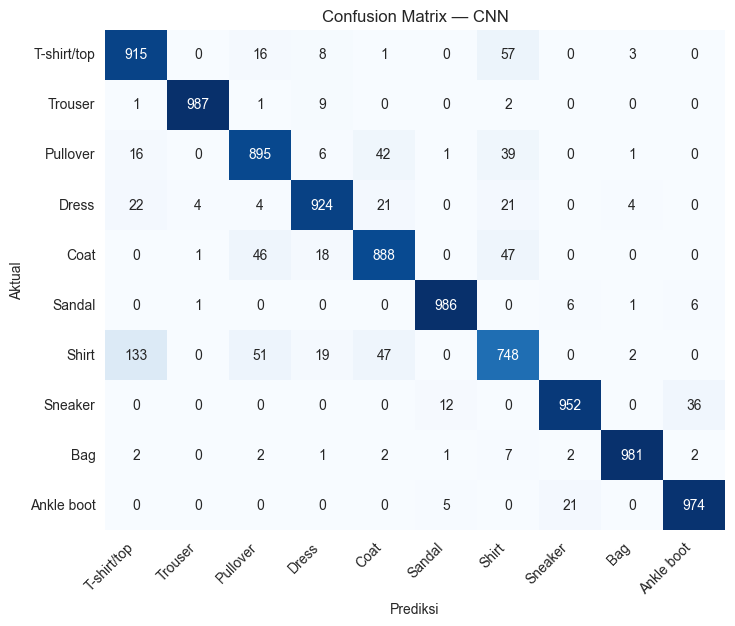

In [7]:
torch.manual_seed(SEED)
cnn = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 32x14x14
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 64x7x7
    nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10))
print(cnn)
h_cnn = fit(cnn, EPOCHS, name="CNN")
plot_history(h_cnn, "CNN Sederhana")
evaluate(cnn, "CNN")

## 7. Model 3 — CNN dengan Batch Normalization dan Dropout

Batch Normalization menstabilkan dan mempercepat training, sedangkan Dropout (pada blok konvolusi dan classifier) mengurangi overfitting.

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Dropout(p=0.25, inplace=False)
  (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Dropout(p=0.25, inplace=False)
  (10): Flatten(start_dim=1, end_dim=-1)
  (11): Linear(in_features=3136, out_features=128, bias=True)
  (12): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (13): ReLU()
  (14): Dropout(p=0.5, inplace=False)
  (15): Linear(in_features=128, out_features=10, bias=True)
)
[CNN+BN+Dropout] epoch 01/12  loss=0.5076 acc=0.8275 | val_lo

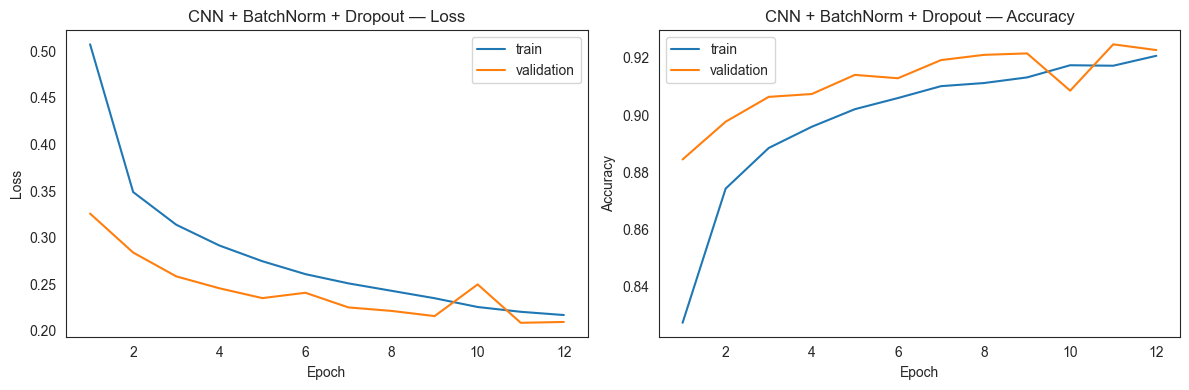

              precision    recall  f1-score   support

 T-shirt/top      0.838     0.908     0.871      1000
     Trouser      0.991     0.988     0.989      1000
    Pullover      0.915     0.860     0.887      1000
       Dress      0.927     0.944     0.936      1000
        Coat      0.874     0.923     0.898      1000
      Sandal      1.000     0.960     0.980      1000
       Shirt      0.825     0.743     0.782      1000
     Sneaker      0.934     0.988     0.960      1000
         Bag      0.986     0.989     0.988      1000
  Ankle boot      0.982     0.965     0.973      1000

    accuracy                          0.927     10000
   macro avg      0.927     0.927     0.926     10000
weighted avg      0.927     0.927     0.926     10000



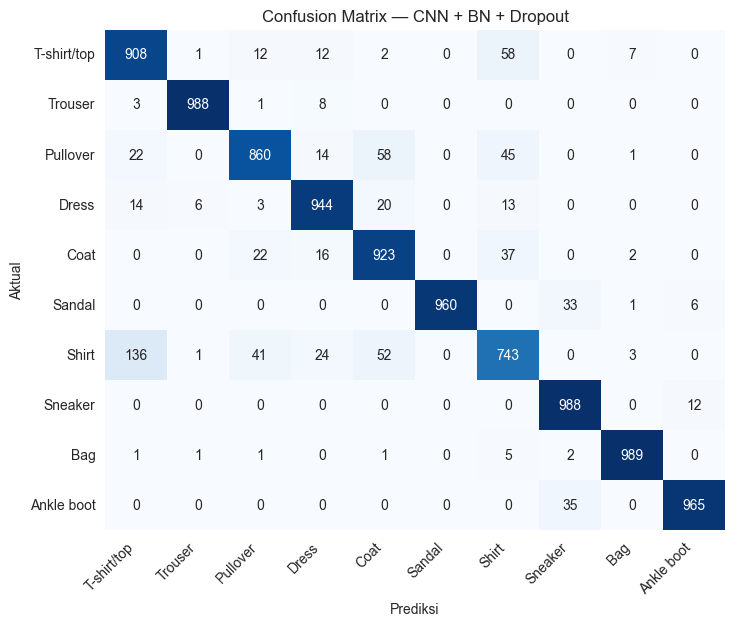

In [8]:
torch.manual_seed(SEED)
cnn_bn = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2), nn.Dropout(0.25),
    nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2), nn.Dropout(0.25),
    nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.5), nn.Linear(128, 10))
print(cnn_bn)
h_bn = fit(cnn_bn, EPOCHS, name="CNN+BN+Dropout")
plot_history(h_bn, "CNN + BatchNorm + Dropout")
evaluate(cnn_bn, "CNN + BN + Dropout")

## 8. Perbandingan Seluruh Model

,Test Accuracy,Macro F1,Params,Waktu Training (s),Gap Train-Val Acc (akhir)
ANN,0.8916,0.8921,"235,146",23,+0.0283
CNN,0.9250,0.9247,"421,642",186,+0.0290
CNN + BN + Dropout,0.9268,0.9263,"422,090",337,-0.0020


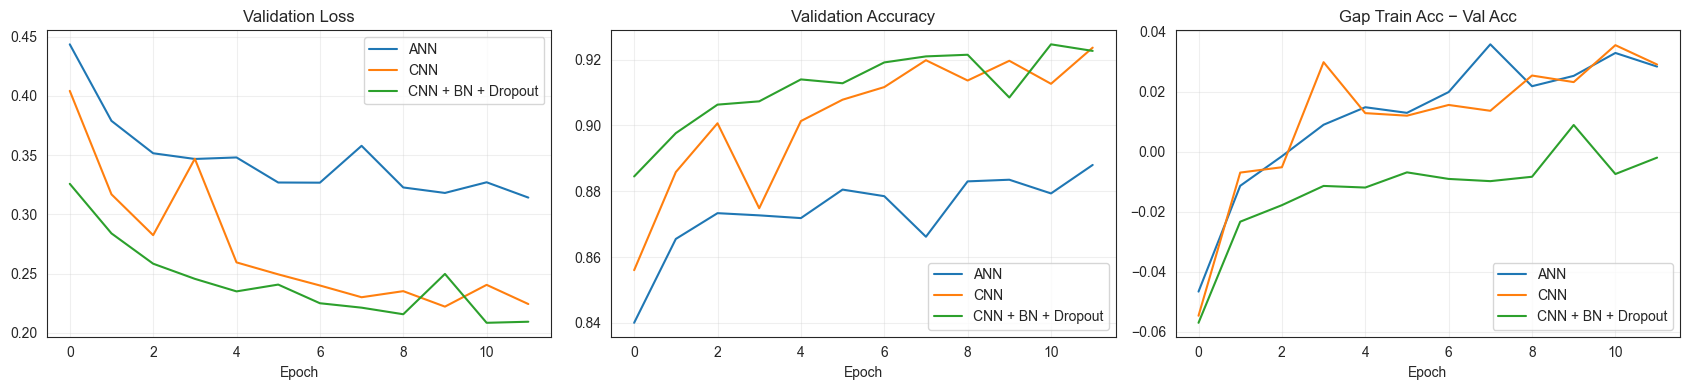

In [9]:
res = pd.DataFrame(results).T
res["Waktu Training (s)"] = [h_ann["time"], h_cnn["time"], h_bn["time"]]
res["Gap Train-Val Acc (akhir)"] = [h["acc"][-1] - h["val_acc"][-1] for h in (h_ann, h_cnn, h_bn)]
display(res.style.format({"Test Accuracy": "{:.4f}", "Macro F1": "{:.4f}", "Params": "{:,.0f}",
                          "Waktu Training (s)": "{:.0f}", "Gap Train-Val Acc (akhir)": "{:+.4f}"}).background_gradient(subset=["Test Accuracy"], cmap="Greens"))

hists = {"ANN": h_ann, "CNN": h_cnn, "CNN + BN + Dropout": h_bn}
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for n, h in hists.items():
    ax[0].plot(h["val_loss"], label=n); ax[1].plot(h["val_acc"], label=n); ax[2].plot(np.array(h["acc"]) - np.array(h["val_acc"]), label=n)
ax[0].set_title("Validation Loss"); ax[1].set_title("Validation Accuracy"); ax[2].set_title("Gap Train Acc − Val Acc")
for a in ax: a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

Model terbaik: CNN + BN + Dropout


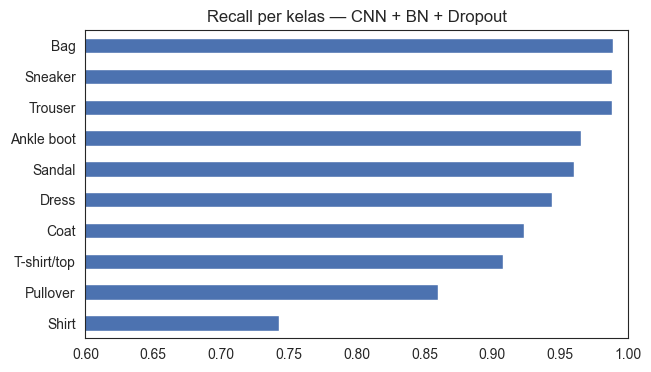

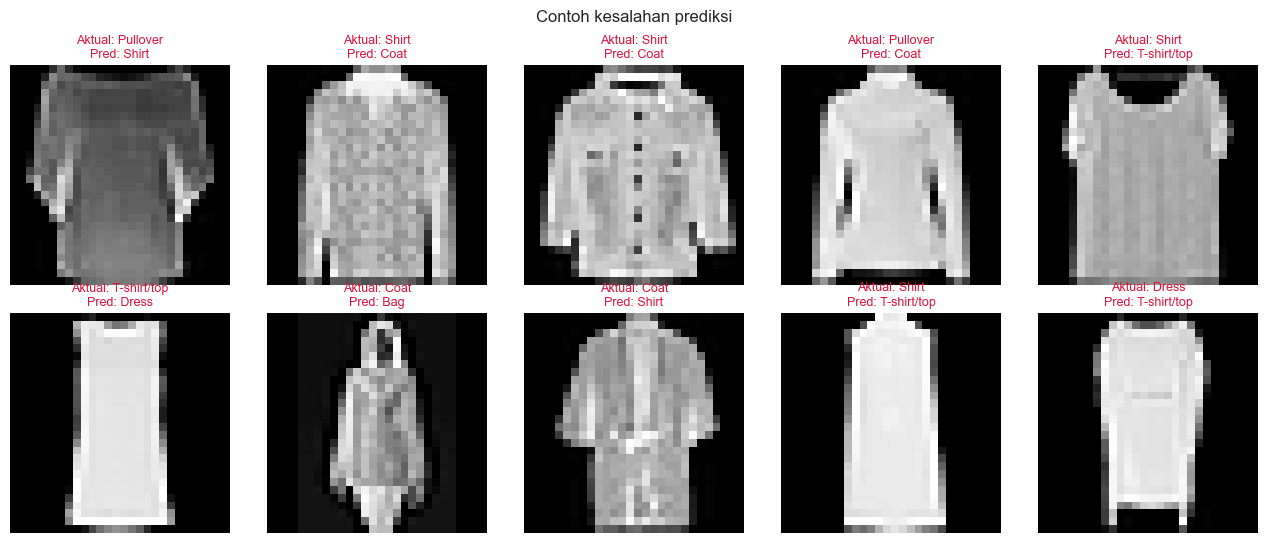

In [10]:
# Kelas yang paling sering salah diprediksi oleh model terbaik
best_name = res["Test Accuracy"].idxmax(); print("Model terbaik:", best_name)
from sklearn.metrics import recall_score
rec = recall_score(y_test, preds[best_name], average=None)
pd.Series(rec, index=CLASS_NAMES).sort_values().plot.barh(figsize=(7, 4), color="#4C72B0"); plt.title(f"Recall per kelas — {best_name}"); plt.xlim(0.6, 1); plt.show()

# Contoh prediksi salah
wrong = np.where(preds[best_name] != y_test)[0][:10]
fig, ax = plt.subplots(2, 5, figsize=(13, 5.5))
for a, i in zip(ax.ravel(), wrong):
    a.imshow(X_test[i].reshape(28, 28), cmap="gray"); a.axis("off")
    a.set_title(f"Aktual: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[preds[best_name][i]]}", fontsize=9, color="crimson")
plt.suptitle("Contoh kesalahan prediksi"); plt.tight_layout(); plt.show()

## 9. Simpan Model Terbaik (untuk Deployment)

Model terbaik disimpan dalam dua format: `state_dict` (butuh definisi arsitektur) dan **TorchScript** (bisa di-load tanpa definisi kelas/arsitektur, praktis untuk deployment).

In [11]:
models = {"ANN": ann, "CNN": cnn, "CNN + BN + Dropout": cnn_bn}
best_model = models[best_name].to("cpu").eval()
torch.save(best_model.state_dict(), "best_model_fashion_mnist.pth")
scripted = torch.jit.trace(best_model, torch.zeros(1, 1, 28, 28)); scripted.save("best_model_fashion_mnist.pt")

# Verifikasi: load kembali & bandingkan akurasi test
loaded = torch.jit.load("best_model_fashion_mnist.pt").eval()
with torch.no_grad():
    p = torch.cat([loaded(xb).argmax(1) for xb, _ in test_loader]).numpy()
print(f"Model tersimpan: {best_name} | akurasi test setelah di-load: {accuracy_score(y_test, p):.4f}")
print("Preprocessing untuk inferensi: piksel dibagi 255.0, input shape (N, 1, 28, 28), kelas =", CLASS_NAMES)

C:\Users\PWK-SN\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\torch\jit\_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
C:\Users\PWK-SN\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\torch\jit\_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
C:\Users\PWK-SN\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Model tersimpan: CNN + BN + Dropout | akurasi test setelah di-load: 0.9268
Preprocessing untuk inferensi: piksel dibagi 255.0, input shape (N, 1, 28, 28), kelas = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## 10. Analisis & Kesimpulan

**a. Tabel hasil (salin angka dari Bagian 8)**

| Model | Test Accuracy | Macro F1 | Jumlah Parameter | Waktu Training | Gap Train–Val |
|---|---|---|---|---|---|
| ANN | 0.8916 | 0.8921 | 235,146 | 23 s | +0.0283 |
| CNN | 0.9250 | 0.9247 | 421,642 | 186 s | +0.0290 |
| CNN + BN + Dropout | **0.9268** | **0.9263** | 422,090 | 337 s | −0.0020 |

*Gap = train accuracy − validation accuracy pada epoch ke-12 (terakhir). Waktu training = 12 epoch, dijalankan di CPU.*

**b. Analisis learning curve**
- Apakah ada overfitting (train accuracy terus naik, val accuracy mendatar/turun) pada ANN dan CNN sederhana? Pada epoch berapa mulai terlihat?
  - **Jawab:** Ya, keduanya menunjukkan overfitting, dengan tingkat yang berbeda.
    - **ANN (ringan):** train accuracy naik terus (0.8934 pada epoch 6 → 0.9163 pada epoch 12), sedangkan val accuracy mendatar di kisaran 0.87–0.89 sejak epoch 3 (bahkan turun ke 0.8662 pada epoch 8). Val loss turun sangat lambat dan bergelombang (0.31–0.36), sementara train loss terus turun (0.2252 vs val loss 0.3142 pada epoch 12). Tanda divergensi mulai terlihat sekitar **epoch 6–7**. Overfitting-nya masih ringan karena kapasitas ANN kecil, sehingga val loss terbaik tetap tercapai di epoch 12.
    - **CNN sederhana (lebih jelas):** train accuracy terus naik sampai 0.9527 dan train loss turun ke 0.1290, tetapi val loss berhenti membaik di **epoch 10** (0.2222; lalu 0.2405 di epoch 11 dan 0.2244 di epoch 12) dan val accuracy stagnan di sekitar 0.91–0.92. Overfitting mulai terlihat sekitar **epoch 8–10**, dan jarak train loss–val loss melebar (0.1290 vs 0.2244). Kurva val loss CNN juga bergelombang (lonjakan ke 0.3470 pada epoch 4).
- Apakah BatchNorm + Dropout membuat kurva lebih stabil dan gap train–val lebih kecil?
  - **Jawab:** Ya, gap menyusut dari +0.0290 (CNN) menjadi −0.0020, dan train loss (0.2169) hampir berimpit dengan val loss (0.2094), jadi tidak ada overfitting dalam 12 epoch. Gap bernilai negatif karena Dropout aktif saat training tetapi nonaktif saat validasi, sehingga train accuracy terukur sedikit lebih rendah. Konvergensi juga lebih cepat: val accuracy epoch 1 sudah 0.8845 (CNN 0.8560, ANN 0.8400). Kurvanya lebih halus, tetapi belum sepenuhnya mulus: masih ada satu lonjakan val loss di epoch 10 (0.2498), walau lebih kecil daripada lonjakan CNN di epoch 4. Pada epoch 12 val accuracy dan train accuracy masih naik, jadi model ini belum jenuh dan masih bisa dilatih lebih lama.

**c. Analisis perbandingan model**
- Mengapa CNN umumnya lebih baik daripada ANN pada data gambar (ingat: ANN meratakan gambar sehingga struktur spasial hilang, CNN memakai filter lokal dan berbagi bobot)?
  - **Jawab:** ANN meratakan gambar menjadi vektor 784 elemen sehingga setiap piksel punya bobot sendiri dan hubungan antar piksel tetangga tidak diketahui model. Pola yang sama (misalnya kerah atau tali sandal) di posisi berbeda harus dipelajari ulang. CNN memakai filter 3×3 lokal yang bobotnya dibagi ke seluruh gambar (*weight sharing*), sehingga pola yang sama dikenali di mana pun posisinya, dan *pooling* membuat fitur lebih tahan terhadap pergeseran kecil. Lapisan bertingkat membangun fitur dari tepi sederhana menjadi bentuk bagian pakaian. Hasilnya test accuracy naik dari 0.8916 ke 0.9250 (+3.3 poin; error turun dari 10.84% ke 7.50%, sekitar 31%). Peningkatan terbesar ada pada kelas pakaian atas: recall T-shirt/top 0.794 → 0.915, Pullover 0.813 → 0.895, Coat 0.838 → 0.888.
- Bandingkan jumlah parameter dan waktu training: apakah peningkatan akurasi sepadan?
  - **Jawab:**
    - **ANN → CNN: sepadan.** Parameter naik sekitar 1,8× (235 rb → 422 rb) dan waktu sekitar 8× (23 s → 186 s), tetapi error turun sekitar 31%. Waktu naik jauh lebih besar daripada parameter karena konvolusi dihitung di setiap posisi gambar, jadi beban komputasinya tidak ditentukan oleh jumlah parameter saja.
    - **CNN → CNN + BN + Dropout: marginal.** BN hanya menambah 448 parameter, tetapi waktu training naik sekitar 1,8× (186 s → 337 s) untuk kenaikan akurasi hanya +0.18 poin (±18 gambar dari 10.000). Selisih sekecil ini bisa masuk rentang variasi antar-seed karena hanya satu kali run. Nilai tambahnya ada pada kestabilan: gap hilang, konvergensi lebih cepat, dan biaya inferensi hampir sama karena jumlah parameter identik dan Dropout nonaktif saat prediksi.
- Kelas mana yang paling sering tertukar (lihat confusion matrix; mis. Shirt vs T-shirt/top vs Pullover vs Coat)? Mengapa menurut kalian?
  - **Jawab:** Kelas **Shirt** paling bermasalah di ketiga model: recall 0.756 (ANN), 0.748 (CNN), 0.743 (CNN+BN+Dropout), dan F1 hanya 0.72–0.78. Pada model terbaik, Shirt paling sering salah diprediksi sebagai T-shirt/top (136), Coat (52), Pullover (41), dan Dress (24). Arah sebaliknya juga terjadi: T-shirt/top → Shirt (58), Pullover → Coat (58) dan → Shirt (45), Coat → Shirt (37). Penyebab yang masuk akal: (1) pakaian atas punya siluet mirip (badan dan lengan); (2) pada resolusi 28×28 grayscale, pembeda utamanya seperti kerah, kancing, ritsleting, panjang lengan, dan tekstur kain hanya tersisa beberapa piksel, dan warna tidak tersedia; (3) kelas Shirt sangat bervariasi sehingga tumpang tindih dengan kelas lain, dan sebagian gambarnya mungkin ambigu bahkan bagi manusia. Menariknya, CNN tidak menaikkan recall Shirt, tetapi precision-nya naik (0.693 → 0.825), artinya CNN lebih berhati-hati melabel Shirt dan gambar yang ragu cenderung dilabel T-shirt/top (recall T-shirt/top naik 0.794 → 0.908). Kelas lain yang sedikit tertukar adalah alas kaki (Ankle boot → Sneaker 35, Sandal → Sneaker 33), tetapi recall-nya tetap ≥ 0.96. Kelas Trouser, Bag, Sandal, dan Ankle boot mudah dikenali karena bentuknya khas (F1 0.94–0.99).

**d. Kesimpulan**
- Model terbaik dan alasannya, serta model yang disimpan untuk tugas Deployment.
  - **Jawab:** Model terbaik adalah **CNN + BatchNorm + Dropout**: test accuracy tertinggi (0.9268), macro F1 tertinggi (0.9263), val loss terendah (0.2085), dan gap train–val paling kecil (−0.0020), artinya generalisasinya paling baik dan paling stabil. Keunggulan atas CNN sederhana memang tipis (+0.18 poin), tetapi model ini dipilih karena kestabilan dan kemampuan generalisasinya, dengan jumlah parameter yang hampir sama. Model ini disimpan sebagai `best_model_fashion_mnist.pth` (state_dict) dan `best_model_fashion_mnist.pt` (TorchScript). Setelah di-load kembali, akurasi test tetap 0.9268, sama dengan hasil evaluasi, jadi penyimpanannya valid. Preprocessing untuk inferensi: piksel dibagi 255.0 dan input berbentuk (N, 1, 28, 28).
- Keterbatasan dan ide perbaikan (data augmentation, learning-rate scheduler, arsitektur lebih dalam, dll.).
  - **Jawab:**
    - **Keterbatasan:** (1) hanya satu run dengan satu seed sehingga selisih CNN vs CNN+BN+Dropout belum tentu signifikan; (2) hanya 12 epoch dan model terbaik masih membaik di akhir; (3) learning rate konstan 1e-3; (4) kelas Shirt masih lemah (recall 0.743); (5) gambar 28×28 grayscale membatasi detail yang bisa dipelajari; (6) gap train–val dihitung dari epoch terakhir, bukan dari checkpoint terbaik yang dipakai untuk evaluasi.
    - **Ide perbaikan:** *data augmentation* (flip horizontal, translasi dan rotasi kecil, random erasing); *learning-rate scheduler* (ReduceLROnPlateau, cosine, atau OneCycle); epoch lebih banyak dengan *early stopping*; arsitektur lebih dalam (blok konvolusi ganda ala VGG, *global average pooling*, atau ResNet kecil); *weight decay* (AdamW); *ensemble* beberapa seed untuk menekan variasi; dan fokus penanganan pada kelompok Shirt–T-shirt–Pullover–Coat, misalnya augmentasi atau loss khusus untuk kelas yang sulit.